In [125]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score)

# Colours and marker shapes for the clusters. Claude was heavely used here to make a standard for readeble grafs.
PALETTE = ["#0000ff", "#ff0000", "#00ff00", "#ff00ff", "#ffff00"]
MARKERS = ["o", "s", "^", "D", "v"]
INK = "#000000"
INK_SOFT = "#555555"

def cluster_legend(ax, labels, centroid=True, loc="upper left"):
    """Build a small and readable legend.

    The handles are made by hand, otherwise matplotlib would copy the large centroid
    marker straight into the legend box where it would cover the data behind it.
    """
    handles = [Line2D([], [], linestyle="none", marker=MARKERS[i], color=PALETTE[i],
                      markersize=6, markeredgecolor="white", label=name)
               for i, name in enumerate(labels)]
    if centroid:
        handles.append(Line2D([], [], linestyle="none", marker="X", color=INK,
                              markersize=8, markeredgecolor="white", label="centroid"))
    ax.legend(handles=handles, loc=loc, fontsize=8, frameon=True, framealpha=0.9,
              facecolor="#fcfcfb", edgecolor="#e6e5e0", borderpad=0.5)


plt.rcParams.update({
    "figure.facecolor": "#ffffff",
    "axes.facecolor": "#ffffff",
    "axes.edgecolor": "#cccccc",
    "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#cccccc",
    "grid.linewidth": 0.8,
    "text.color": INK,
    "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT,
    "font.size": 10,
    "figure.dpi": 110,
})

print("Libraries loaded")

Libraries loaded


## Part 1 The algorithm written from scratch

K Means tries to split the data into `k` groups so that the points inside a group lie as close as
possible to the middle point of that group. The middle point is called a centroid. The algorithm
repeats two simple steps until nothing moves any more.

**Step 0 Random initialisation.** Pick `k` of the data points at random and use them as the first
centroids. Picking real data points instead of random coordinates is a safe choice, because a
centroid then always starts inside the cloud of data.

**Step 1 Assignment.** Measure the Euclidean distance from every point to every centroid and give
each point the label of the centroid closest to it.

**Step 2 Update.** Move every centroid to the mean position of the points that were given to it.
If a cluster ends up with no points at all, the centroid is moved to a random data point so the
run can continue with the full number of clusters.

**Step 3 Stopping rule.** Stop when the largest movement of a centroid in one round is smaller
than a small threshold called `tol`, or when the number of rounds reaches `max_iter`. The first
condition means that the algorithm has settled, the second one guarantees that the loop always
ends.

**Quality of a solution.** The sum of the squared distances from every point to its own centroid
is called the inertia. Lower is better. K Means can settle in a poor solution if the random start
was unlucky, so the whole procedure is repeated `n_init` times with different random starts and
the run with the lowest inertia is kept.

In [126]:
# The three building blocks of K Means

def init_centroids(X, k, rng):
    idx = rng.choice(X.shape[0], size=k, replace=False)
    return X[idx].copy()


def assign_clusters(X, centroids):
    diff = X[:, np.newaxis, :] - centroids[np.newaxis, :, :]
    distances = np.sqrt(np.sum(diff ** 2, axis=2))   # Euclidean distance
    labels = np.argmin(distances, axis=1)            # index of the closest centroid
    closest = np.min(distances, axis=1)              # distance to that centroid
    return labels, closest


def update_centroids(X, labels, centroids, rng):
    new_centroids = np.empty_like(centroids)
    for c in range(centroids.shape[0]):
        points = X[labels == c]
        if len(points) == 0:
            # Empty cluster. Restart this centroid on a random data point.
            new_centroids[c] = X[rng.integers(X.shape[0])]
        else:
            new_centroids[c] = points.mean(axis=0)
    return new_centroids

print("Loaded")

Loaded


In [127]:
# The algorithm

class KMeansScratch:

    def __init__(self, k, max_iter=300, tol=1e-6, n_init=10, random_state=0):
        self.k = k                       # number of clusters
        self.max_iter = max_iter         # hard limit on the number of rounds
        self.tol = tol                   # stop when the centroids move less than this
        self.n_init = n_init             # number of random restarts
        self.random_state = random_state # makes the notebook reproducible

    def _single_run(self, X, rng):
        centroids = init_centroids(X, self.k, rng)
        history = []                     # inertia after every round, useful to show convergence
        n_rounds = 0

        for _ in range(self.max_iter):
            n_rounds += 1
            labels, closest = assign_clusters(X, centroids)          # step 1
            history.append(float(np.sum(closest ** 2)))
            new_centroids = update_centroids(X, labels, centroids, rng)  # step 2
            shift = np.sqrt(np.sum((new_centroids - centroids) ** 2, axis=1)).max()
            centroids = new_centroids
            if shift < self.tol:                                     # step 3, it has settled
                break

        labels, closest = assign_clusters(X, centroids)   # final labels for the final centroids
        inertia = float(np.sum(closest ** 2))
        return centroids, labels, inertia, n_rounds, history

    def fit(self, X):
        rng = np.random.default_rng(self.random_state)
        best = None
        self.all_inertias_ = []

        for _ in range(self.n_init):
            result = self._single_run(X, rng)
            self.all_inertias_.append(result[2])
            if best is None or result[2] < best[2]:
                best = result

        self.centroids_, self.labels_, self.inertia_, self.n_iter_, self.history_ = best
        return self

    def predict(self, X):
        labels, _ = assign_clusters(X, self.centroids_)
        return labels

print("Loaded")

Loaded


### A check on artificial data

Before touching the Iris data I want to test the code on something where the right answer is
obvious. Three well separated clouds of points are created and the algorithm is asked for three
clusters. If the implementation works, it should find exactly those three clouds.

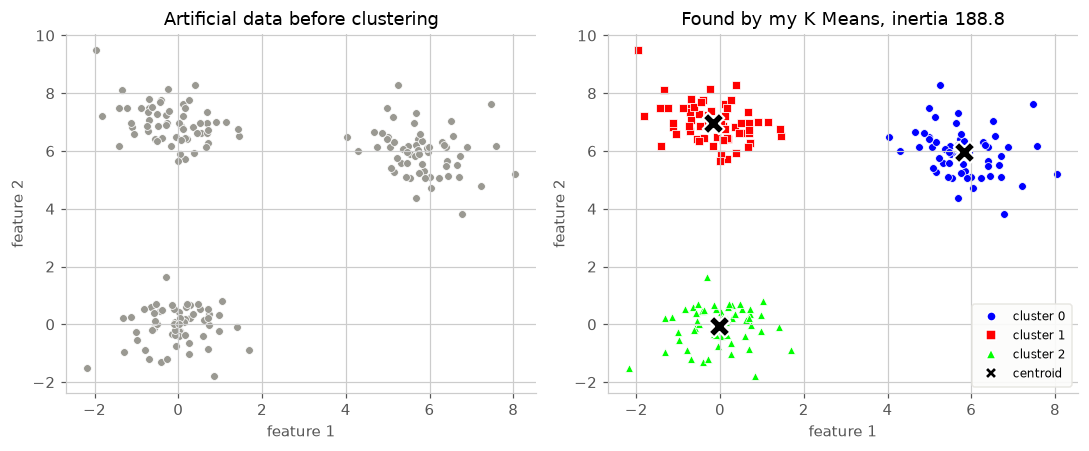

Rounds until the centroids stopped moving: 4
Centroids found by my implementation:
[[-0.17 -0.05]
 [-0.03  5.95]
 [ 5.82  6.98]]
True centres used when the data was made:
[[0. 0.]
 [0. 6.]
 [6. 7.]]


In [128]:
# TEST
rng_demo = np.random.default_rng(1)
true_centers = np.array([[0.0, 0.0], [6.0, 6.0], [0.0, 7.0]])
X_demo = np.vstack([c + rng_demo.normal(0, 0.8, size=(60, 2)) for c in true_centers])

demo = KMeansScratch(k=3, random_state=1).fit(X_demo)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

axes[0].scatter(X_demo[:, 0], X_demo[:, 1], s=26, color="#9a9992", edgecolor="white", linewidth=0.5)
axes[0].set_title("Artificial data before clustering")

for c in range(demo.k):
    mask = demo.labels_ == c
    axes[1].scatter(X_demo[mask, 0], X_demo[mask, 1], s=26, color=PALETTE[c],
                    marker=MARKERS[c], edgecolor="white", linewidth=0.5)
axes[1].scatter(demo.centroids_[:, 0], demo.centroids_[:, 1], s=200, marker="X",
                color=INK, edgecolor="white", linewidth=1.4, zorder=5)
axes[1].set_title(f"Found by my K Means, inertia {demo.inertia_:.1f}")
cluster_legend(axes[1], [f"cluster {c}" for c in range(demo.k)], loc="lower right")

for ax in axes:
    ax.set_xlabel("feature 1")
    ax.set_ylabel("feature 2")

plt.tight_layout()
plt.show()

print(f"Rounds until the centroids stopped moving: {demo.n_iter_}")
print("Centroids found by my implementation:")
print(np.round(np.sort(demo.centroids_, axis=0), 2))
print("True centres used when the data was made:")
print(np.round(np.sort(true_centers, axis=0), 2))

The three clouds look good and the centroids land almost exactly on the centres that were used
to create the data.

## Part 2 The Iris dataset

Iris holds 150 flowers described by four measurements in centimetres. The dataset also has a
species label with three classes, but clustering is unsupervised, so the label is kept completely
out of the algorithm. It is only used at the very end to see whether the clusters happen to agree
with the species.

In [129]:
# Load the Iris data
iris = load_iris()
X = iris.data                  # the four feature columns, this is all the algorithm ever sees
y_true = iris.target           # species, used only for the comparison at the end
feature_names = iris.feature_names
species_names = iris.target_names

iris_df = pd.DataFrame(X, columns=feature_names)
iris_df["species"] = species_names[y_true]

print(f"Shape of the feature matrix: {X.shape}")
print(f"Features: {feature_names}")
print(f"Species in the file: {list(species_names)}, {np.bincount(y_true)} flowers of each")
iris_df.head(150)

Shape of the feature matrix: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Species in the file: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')], [50 50 50] flowers of each


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [130]:
# A look at the numbers
iris_df.describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


In [131]:
# A "two" dimensional view of the "four" dimensional data
pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X)

explained = pca.explained_variance_ratio_
print(f"Variance kept by component 1: {explained[0]:.1%}")
print(f"Variance kept by component 2: {explained[1]:.1%}")
print(f"Variance kept by the two components together: {explained.sum():.1%}")

Variance kept by component 1: 92.5%
Variance kept by component 2: 5.3%
Variance kept by the two components together: 97.8%


The two components keep almost 98 percent of the variation in the data, so the flat picture is a
very honest summary of the real four dimensional shape.

## Part 3 Running the algorithm with different values of k

The algorithm is now run with k equal to 2, 3, 4 and 5. Each run uses ten random restarts and the
best of them is kept. For every value of k the notebook reports the inertia, the number of rounds
needed before the centroids stopped moving, the size of each cluster and the silhouette score.

The silhouette score compares how close a point is to its own cluster with how close it is to the
nearest other cluster. It runs from minus one to plus one and a higher value means better
separated clusters.

In [132]:
# Run my K Means for several values of k
k_values = [2, 3, 4, 5]
models = {}
rows = []

for k in k_values:
    model = KMeansScratch(k=k, n_init=10, random_state=42).fit(X)
    models[k] = model
    rows.append({
        "k": k,
        "inertia": round(model.inertia_, 2),
        "silhouette": round(silhouette_score(X, model.labels_), 3),
        "rounds": model.n_iter_,
        "cluster sizes": list(np.bincount(model.labels_)),
    })

summary = pd.DataFrame(rows).set_index("k")
summary

,inertia,silhouette,rounds,cluster sizes
k,,,,
2,152.35,0.681,2,"[53, 97]"
3,78.85,0.553,4,"[50, 38, 62]"
4,57.23,0.498,5,"[40, 50, 28, 32]"
5,46.45,0.489,9,"[12, 25, 24, 50, 39]"


### Visualisation in the petal feature space

The first plot shows the clusters using petal length and petal width, the two features that
separate the Iris flowers best. The black cross marks the centroid of each cluster, drawn at its
petal coordinates.

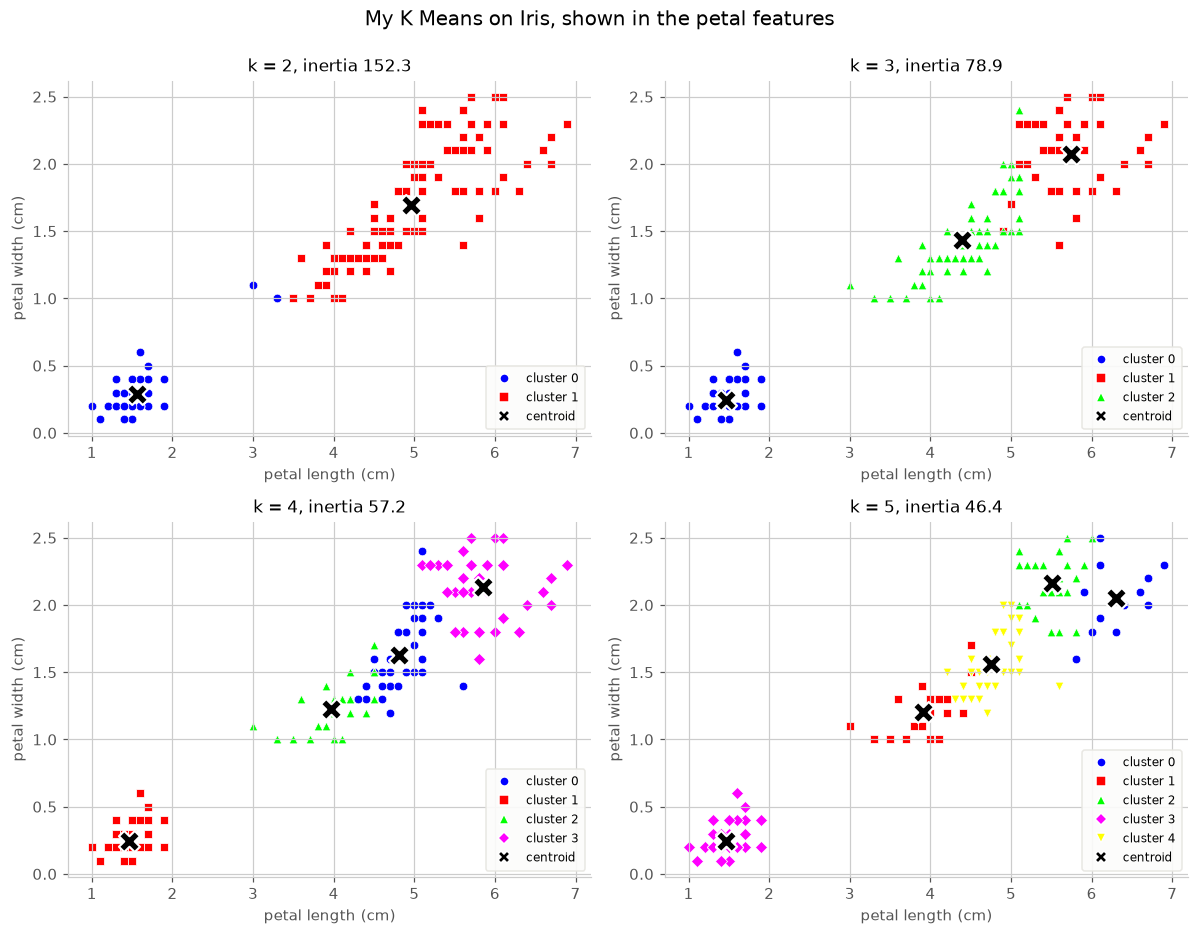

In [133]:
# Helper used by the plots below. Claude was heavely used here.
def draw_clusters(ax, points, labels, centroid_points, title, xlabel, ylabel, names=None):
    if names is None:
        names = [f"cluster {c}" for c in range(centroid_points.shape[0])]
    for c in range(centroid_points.shape[0]):
        mask = labels == c
        ax.scatter(points[mask, 0], points[mask, 1], s=32, color=PALETTE[c], marker=MARKERS[c],
                   edgecolor="white", linewidth=0.5)
    ax.scatter(centroid_points[:, 0], centroid_points[:, 1], s=190, marker="X", color=INK,
               edgecolor="white", linewidth=1.4, zorder=5)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    cluster_legend(ax, names, loc="lower right")


# Petal length against petal width, one panel per value of k
pl, pw = 2, 3   # column numbers of petal length and petal width

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
for ax, k in zip(axes.ravel(), k_values):
    model = models[k]
    draw_clusters(ax, X[:, [pl, pw]], model.labels_, model.centroids_[:, [pl, pw]],
                  f"k = {k}, inertia {model.inertia_:.1f}",
                  feature_names[pl], feature_names[pw])

fig.suptitle("My K Means on Iris, shown in the petal features", fontsize=13, y=0.995)
plt.tight_layout()
plt.show()

### Visualisation in the PCA projection

The same four results are drawn again, this time in the PCA projection so that all four features
take part in the picture. The centroids are pushed through the same PCA transformation.

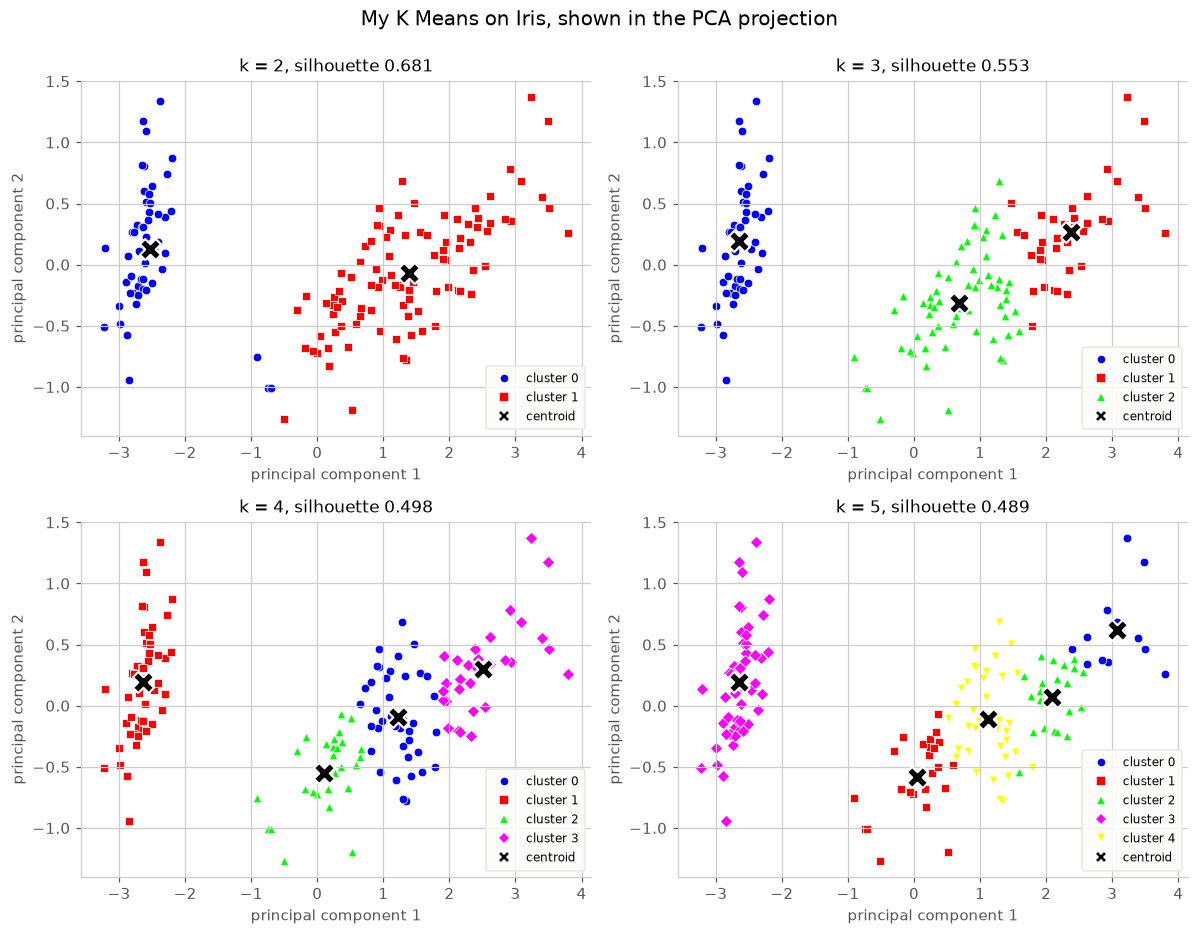

In [134]:
# The same runs shown in the PCA projection
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
for ax, k in zip(axes.ravel(), k_values):
    model = models[k]
    draw_clusters(ax, X_pca, model.labels_, pca.transform(model.centroids_),
                  f"k = {k}, silhouette {silhouette_score(X, model.labels_):.3f}",
                  "principal component 1", "principal component 2")

fig.suptitle("My K Means on Iris, shown in the PCA projection", fontsize=13, y=0.995)
plt.tight_layout()
plt.show()

## Choosing a value for k

Five tools to pick a value.

The **elbow method** plots the inertia against k. Inertia always falls when k grows, because more
centroids means shorter distances, so the interesting thing is not the lowest point but the place
where the curve suddenly flattens out. That bend is the point where extra clusters stop buying
much.

The **silhouette score** is plotted next to it. Here a high value is the good one.

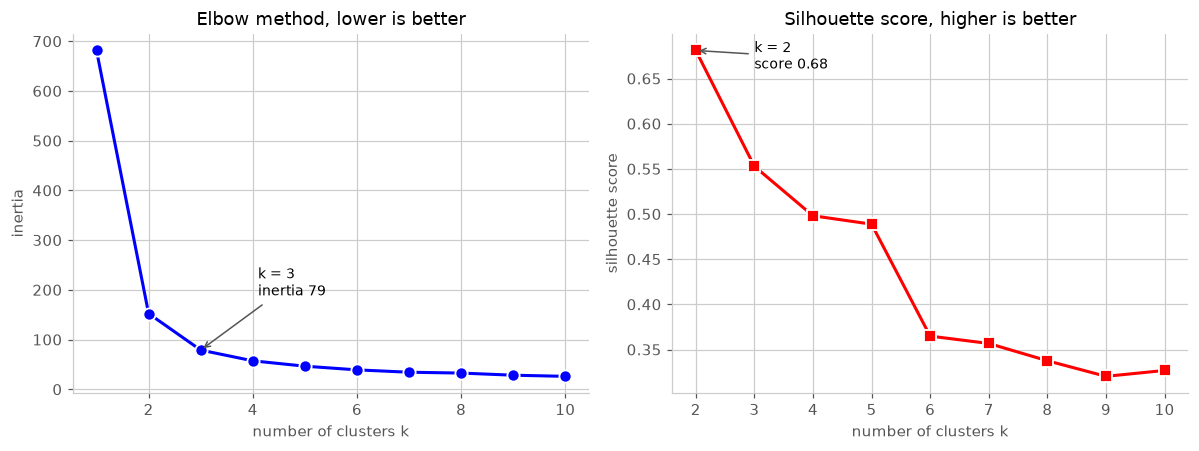

,inertia,silhouette
k,,
1,681.37,NaN
2,152.35,0.681
3,78.85,0.553
4,57.23,0.498
5,46.45,0.489
6,39.04,0.365
7,34.30,0.357
8,32.61,0.338
9,28.31,0.320


In [135]:
# Elbow curve and silhouette curve
k_range = list(range(1, 11))
inertias = []
silhouettes = []

for k in k_range:
    model = KMeansScratch(k=k, n_init=10, random_state=42).fit(X)
    inertias.append(model.inertia_)
    # The silhouette score needs at least two clusters.
    silhouettes.append(silhouette_score(X, model.labels_) if k > 1 else np.nan)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].plot(k_range, inertias, color=PALETTE[0], linewidth=2, marker="o", markersize=8,
             markeredgecolor="white", markeredgewidth=1.2)
axes[0].set_title("Elbow method, lower is better")
axes[0].set_xlabel("number of clusters k")
axes[0].set_ylabel("inertia")
axes[0].annotate(f"k = 3\ninertia {inertias[2]:.0f}", xy=(3, inertias[2]),
                 xytext=(4.1, inertias[2] + 110), color=INK, fontsize=9,
                 arrowprops=dict(arrowstyle="->", color=INK_SOFT))

axes[1].plot(k_range[1:], silhouettes[1:], color=PALETTE[1], linewidth=2, marker="s", markersize=8,
             markeredgecolor="white", markeredgewidth=1.2)
axes[1].set_title("Silhouette score, higher is better")
axes[1].set_xlabel("number of clusters k")
axes[1].set_ylabel("silhouette score")
axes[1].annotate(f"k = 2\nscore {silhouettes[1]:.2f}", xy=(2, silhouettes[1]),
                 xytext=(3.0, silhouettes[1] - 0.02), color=INK, fontsize=9,
                 arrowprops=dict(arrowstyle="->", color=INK_SOFT))

plt.tight_layout()
plt.show()

pd.DataFrame({"k": k_range, "inertia": np.round(inertias, 2),
              "silhouette": np.round(silhouettes, 3)}).set_index("k")

It drops steeply from k equal to 1 down to k equal to 3 and after that the curve becomes
almost a straight and gentle slope. The bend therefore sits at k equal to 3.

The silhouette score instead has its highest value at k equal to 2. The two measures disagree, and
the reason becomes clear in the next section.

Because the two measures disagree, it is worth asking a few more measures what they think before
the value of k is settled.

### Three more ways to judge k

The **Calinski Harabasz index** divides the spread between the clusters by the spread inside them.
A high value means the clusters sit far from each other and are tight in themselves.

The **Davies Bouldin index** looks at every cluster together with the cluster most similar to it
and measures how much the pair overlaps. Here a low value is the good one.

**Stability** does not come from a library. The same value of k is run from five different random
starts and every pair of runs is compared with the adjusted Rand index, which measures how much
two labellings agree without caring about the cluster numbers. If a value of k describes real
structure in the data, all the runs should land in the same solution and the value should sit
close to 1. If the clusters are invented by the algorithm rather than found in the data, the runs
disagree and the value drops.

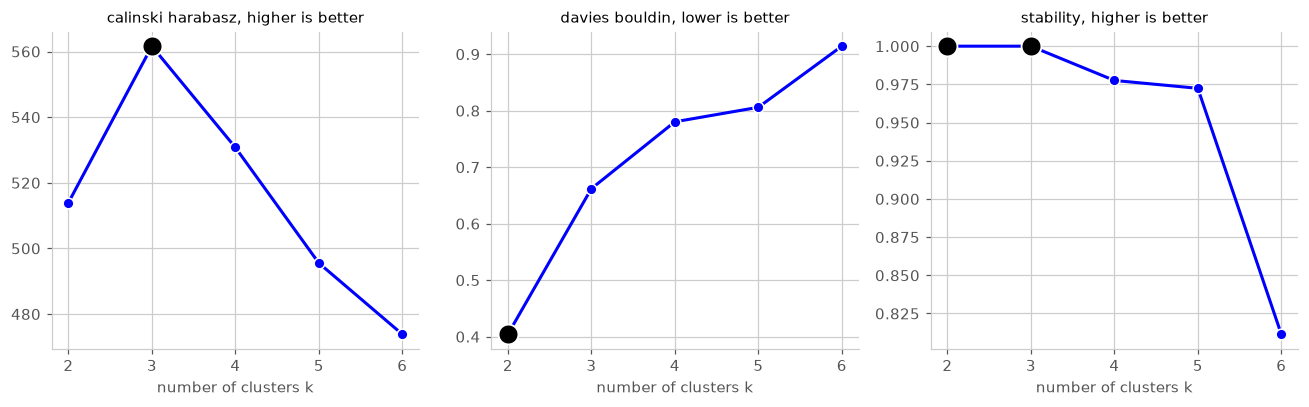

,silhouette,calinski harabasz,davies bouldin,stability
k,,,,
2,0.681,513.925,0.404,1.000
3,0.553,561.628,0.662,1.000
4,0.498,530.766,0.780,0.978
5,0.489,495.541,0.806,0.972
6,0.365,473.851,0.914,0.811


In [136]:
# Calinski Harabasz, Davies Bouldin and stability across random starts
extra_rows = []

for k in range(2, 7):
    model = KMeansScratch(k=k, n_init=10, random_state=42).fit(X)

    # Stability. Run the same k from five different random starts and compare every pair of runs.
    seed_labels = [KMeansScratch(k=k, n_init=10, random_state=s).fit(X).labels_ for s in range(5)]
    pair_scores = [adjusted_rand_score(seed_labels[i], seed_labels[j])
                   for i in range(len(seed_labels)) for j in range(i + 1, len(seed_labels))]

    extra_rows.append({
        "k": k,
        "silhouette": silhouette_score(X, model.labels_),
        "calinski harabasz": calinski_harabasz_score(X, model.labels_),
        "davies bouldin": davies_bouldin_score(X, model.labels_),
        "stability": float(np.mean(pair_scores)),
    })

extra = pd.DataFrame(extra_rows).set_index("k")

# One panel per measure, because the three measures live on completely different scales and would
# be impossible to read on a shared axis. The black dot marks the best value of each measure.
panels = [("calinski harabasz", "higher is better", np.argmax),
          ("davies bouldin", "lower is better", np.argmin),
          ("stability", "higher is better", np.argmax)]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, note, pick) in zip(axes, panels):
    values = extra[name].values
    # Two values of k can tie, so every k that reaches the best value gets a black dot.
    best_value = values[int(pick(values))]
    is_best = np.isclose(values, best_value, rtol=1e-3)
    ax.plot(extra.index, values, color=PALETTE[0], linewidth=2, marker="o", markersize=7,
            markeredgecolor="white", markeredgewidth=1.0)
    ax.plot(extra.index[is_best], values[is_best], linestyle="none", marker="o", markersize=13,
            color=INK, markeredgecolor="white", markeredgewidth=1.2, zorder=5)
    ax.set_title(f"{name}, {note}", fontsize=10)
    ax.set_xlabel("number of clusters k")
    ax.set_xticks(list(extra.index))

plt.tight_layout()
plt.show()

extra.round(3)

Calinski Harabasz has its highest value at k equal to 3 and falls away on both sides, so it points
at the same value as the elbow plot. Davies Bouldin is lowest at k equal to 2 and therefore sides
with the silhouette score. Stability is perfect at both k equal to 2 and k equal to 3, which means
every random start finds the same solution for those two values, and it starts to fall from k
equal to 4 and breaks down at k equal to 6. That is a clear sign that the extra clusters above 3
are not found in the data but invented by the algorithm, and that they land in a different place
every time it is run.

The score board is now two measures pointing at k equal to 3, the elbow and Calinski Harabasz,
against two pointing at k equal to 2, the silhouette and Davies Bouldin. Stability does not
separate the two candidates, since both of them are perfectly stable, but it does rule out every
value above 3.

## Comparing the clusters with the real species

The species labels were never given to the algorithm. Comparing them with the clusters afterwards
shows how much of the real structure K Means managed to recover on its own. Cluster numbers are
arbitrary, so each cluster is matched with the species that is most common inside it. In the plot
further down the colours are lined up in the same way, so the two panels can be compared directly.

In [137]:
# How well do the clusters match the species?
def compare_with_species(model, k):
    table = pd.crosstab(pd.Series(species_names[y_true], name="species"),
                        pd.Series(model.labels_, name="cluster"))
    # Each cluster is credited with its most common species.
    agreement = table.values.max(axis=0).sum() / len(y_true)

    # The adjusted Rand index and the normalized mutual information compare the clustering with
    # the species without caring about the cluster numbers, and both of them correct for the
    # agreement that would happen by pure chance.
    ari = adjusted_rand_score(y_true, model.labels_)
    nmi = normalized_mutual_info_score(y_true, model.labels_)

    print(f"k = {k}, agreement {agreement:.1%}, "
          f"adjusted Rand index {ari:.3f}, normalized mutual information {nmi:.3f}")
    return table

for k in k_values:
    display(compare_with_species(models[k], k))
    print()

k = 2, agreement 66.7%, adjusted Rand index 0.540, normalized mutual information 0.657


cluster,0,1
species,,
setosa,50,0
versicolor,3,47
virginica,0,50



k = 3, agreement 89.3%, adjusted Rand index 0.730, normalized mutual information 0.758


cluster,0,1,2
species,,,
setosa,50,0,0
versicolor,0,2,48
virginica,0,36,14



k = 4, agreement 88.0%, adjusted Rand index 0.650, normalized mutual information 0.722


cluster,0,1,2,3
species,,,,
setosa,0,50,0,0
versicolor,23,0,27,0
virginica,17,0,1,32



k = 5, agreement 90.7%, adjusted Rand index 0.608, normalized mutual information 0.694


cluster,0,1,2,3,4
species,,,,,
setosa,0,0,0,50,0
versicolor,0,24,0,0,26
virginica,12,1,24,0,13


Flowers placed in the cluster of another species: 16 out of 150


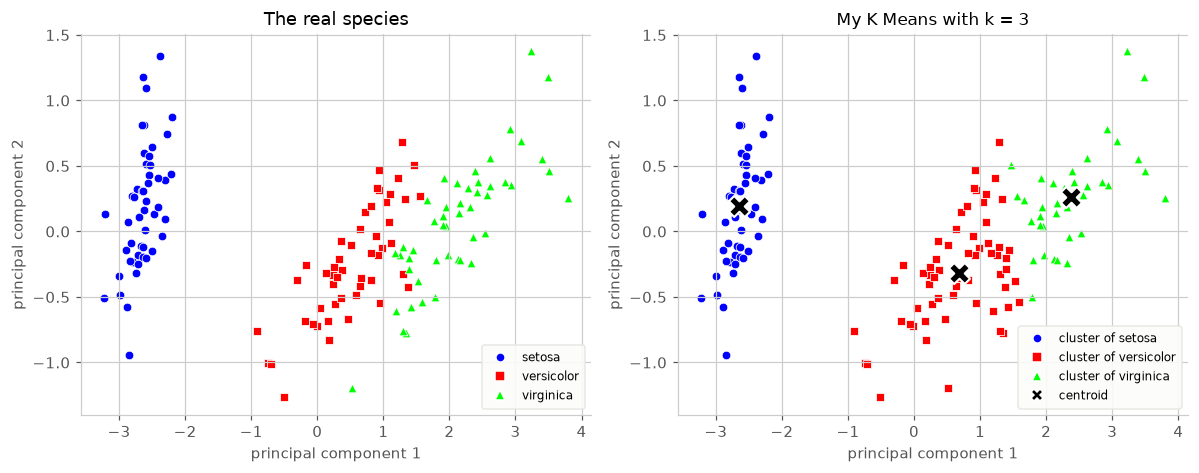

In [138]:
# The real species next to the clustering with k equal to 3
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

for i, name in enumerate(species_names):
    mask = y_true == i
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], s=32, color=PALETTE[i], marker=MARKERS[i],
                    edgecolor="white", linewidth=0.5)
axes[0].set_title("The real species")
cluster_legend(axes[0], list(species_names), centroid=False, loc="lower right")

model3 = models[3]

# The cluster numbers themselves mean nothing, so every cluster is renumbered after the species
# that is most common inside it. Then the same species has the same colour in both panels and the
# two pictures can be read side by side.
cluster_to_species = [np.bincount(y_true[model3.labels_ == c], minlength=3).argmax()
                      for c in range(model3.k)]
aligned_labels = np.array(cluster_to_species)[model3.labels_]

centroids_pca = pca.transform(model3.centroids_)
centroids_aligned = np.empty_like(centroids_pca)
for c, s in enumerate(cluster_to_species):
    centroids_aligned[s] = centroids_pca[c]

draw_clusters(axes[1], X_pca, aligned_labels, centroids_aligned,
              "My K Means with k = 3", "principal component 1", "principal component 2",
              names=[f"cluster of {name}" for name in species_names])

wrong = int(np.sum(aligned_labels != y_true))
print(f"Flowers placed in the cluster of another species: {wrong} out of {len(y_true)}")

for ax in axes:
    ax.set_xlabel("principal component 1")
    ax.set_ylabel("principal component 2")

plt.tight_layout()
plt.show()

## Part 4 Discussion

### How does the choice of k affect the clustering results?

The value of k decides everything about the result, because the algorithm never questions the
number it is given. It will always produce exactly k groups, even when the data contains a
different number of natural groups, so k is really a statement about how fine or how coarse the
description of the data should be.

With k equal to 2 the algorithm makes one clean cut. Setosa is placed alone on one side and the
two other species are merged into a single large cluster on the other side. This is the most
obvious split in the data and it gives the highest silhouette score, 0.68, because the two groups
are far apart and each of them is compact seen from the outside. The price is that real structure
is thrown away, since two different species end up under the same label.

With k equal to 3 the large cluster is broken into two parts along the petal measurements. The
inertia falls sharply from 152 to 79, which means the new centroid explains a large amount of the
spread that was left over. The silhouette drops to 0.55, but that fall is not a sign of failure.
It happens because the two new clusters are neighbours that touch each other, and the silhouette
measure always punishes neighbouring clusters even when the split is correct.

With k equal to 4 and k equal to 5 the inertia keeps falling, to 57 and to 46, but the fall is
much slower and no new group is discovered. The extra centroids do not travel to a hidden species.
They move into the dense and stretched region where versicolor and virginica sit, and they cut
that region into thinner slices. At k equal to 4 the virginica flowers are divided over two
clusters, and at k equal to 5 both versicolor and virginica are cut in two, so a single species is
then described by two different labels. Setosa keeps its own clean cluster of 50 flowers at every
value of k, because it is the only group that is really separated from the rest. This is over
clustering. The numbers look better while the interpretation gets worse, which is exactly why
inertia alone can never be used to choose k.

Two more practical effects are worth noting. Higher k makes the runs slower and more sensitive to
the random start, which is visible in the number of rounds needed before the centroids stop
moving, rising from 2 rounds at k equal to 2 to 9 rounds at k equal to 5. And since K Means can
settle in a poor solution depending on where the centroids happen to start, the ten random
restarts in my implementation matter more and more as k grows.

### Which value of k seems most appropriate for the Iris dataset?

k equal to 3 is the best choice.

The elbow plot points at it, because the inertia curve bends clearly at 3 and is almost a straight
line afterwards. Going from 2 to 3 clusters lowers the inertia by more than 70 units, while every
cluster added after that gives around 20 units or less and the gain keeps shrinking. The clusters at k equal to 3 are also easy to explain
in words. One group has small petals, one has medium petals and one has large petals, and every
group has a reasonable size of 50, 62 and 38 flowers.

Two of the extra measures agree. The Calinski Harabasz index has its top value at k equal to 3,
and the stability test shows that every random start finds the same three clusters, while the
runs begin to disagree with each other from k equal to 4 and fall apart at k equal to 6. A number
of clusters that is found again and again from different starting points is a much better sign of
real structure than a good score from one single run.

The silhouette score prefers k equal to 2, and the Davies Bouldin index agrees with it. That is a
fair objection, but both of them answer a slightly different question. Silhouette rewards clusters that are far away from each other, so it will
always favour the single most obvious split in the data. In Iris that split hides the fact that
the large cluster really consists of two overlapping groups. When the two measures disagree in
this way, the choice should be made together with knowledge about the data and about what the
clustering is going to be used for, and not by the score alone.

### How does this relate to the known number of classes in the Iris dataset?

Iris has three species, so k equal to 3 agrees exactly with the number of classes that is known to
exist in the data. That is a pleasing result, since the algorithm was never shown a single label.
It found the correct number of groups purely from the geometry of the measurements.

The comparison table shows how far the agreement goes. With k equal to 3 about 89 percent of the
flowers land in the cluster belonging to their own species. Setosa is recovered perfectly, all 50
flowers in one cluster and no other flower in it, because setosa has clearly smaller petals than
the rest. Versicolor and virginica are the problem. Their measurements overlap in the middle
region, so roughly 16 flowers are placed in the neighbouring cluster. K Means draws a straight
border halfway between two centroids and can do no better when the real groups run into each
other.

With k equal to 2 the agreement is only 67 percent, because versicolor and virginica share one
cluster and one of them must always be counted as wrong. Going the other way, k equal to 4 and k
equal to 5 do not really improve anything. The agreement number even creeps up to 90.7 percent at
k equal to 5, but that is an artefact of the way the number is built. Every cluster is credited
with its own most common species, so the score can almost only rise when clusters are added, and
with 150 clusters it would reach 100 percent while saying nothing at all. The tables behind the
number show what actually happens. One species is spread over two clusters, which is a different
kind of mistake than the one made at k equal to 2 but it is still a mistake.

The adjusted Rand index does not suffer from that weakness, because it corrects for the agreement
that would appear by pure chance and it punishes a species that is cut over several clusters. It
reaches its highest value of 0.730 at k equal to 3 and falls for every larger k, down to 0.608 at
k equal to 5. The normalized mutual information behaves in exactly the same way. So the moment the
comparison is done with a measure that cannot be fooled by extra clusters, k equal to 3 comes out
on top there as well.

It is important not to read too much into the match. K Means has no idea what a species is. It
only groups points that lie close together, and the reason the result agrees so well with the
species is that the flowers of one species really do have similar petal and sepal measurements. If
the species had been separated by something the four features do not measure, the algorithm would
have found the same three geometric groups and they would have meant nothing.

## Summary

The algorithm was written from scratch with random initialisation, assignment to the closest
centroid, an update of the centroids to the mean of their points and a stopping rule based on
centroid movement together with an upper limit on the number of rounds. The inertia my
implementation reaches on Iris with k equal to 3 is 78.85, which is the same value that the
standard library implementation reaches, so the implementation is correct and not only plausible.

Applied to Iris, the algorithm finds three groups that correspond closely to the three real
species, and k equal to 3 is the value supported both by the elbow plot and by what is known about
the data.

## AI DECLARATION

### Ai (Claude) was used to/when
 `1`. I was stuck

 `2`. Grammer

 `3`. Adding coments in code

 `4`. Formating nice looking Markdown parts

 `5`. Give better names to varibels where i was lazy